# Alphabet After the Print: The Marks Cut Both Ways

Blog post data. Every figure in the post's charts and text, with its source, the calculations behind the derived
numbers, a check that each published number ties to the data, and the four charts redrawn in matplotlib.

Data as of the October 29, 2026 close. Quarterly figures are in millions of dollars unless stated.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

BLUE_MAIN, BLUE_SOFT, BLUE_LIGHT = "#005a96", "#0f80c4", "#8fd1ff"
TITLE_BLUE, TEXT_MAIN, TEXT_MUTED, RED_SOFT = "#13597B", "#0f172a", "#4b5563", "#dc2626"

plt.rcParams.update({
    "font.family":        "serif",
    "font.serif":         ["Garamond", "Georgia", "Times New Roman", "serif"],
    "axes.spines.top":    False,
    "axes.spines.right":  False,
    "axes.grid":          False,
    "figure.facecolor":   "white",
    "axes.facecolor":     "white",
    "axes.edgecolor":     TEXT_MUTED,
    "xtick.color":        TEXT_MAIN,
    "ytick.color":        TEXT_MAIN,
    "text.color":         TEXT_MAIN,
})

## Sources

| Key | Source |
|---|---|
| Q3'25, Q3'26 | Alphabet, "Alphabet Announces Third Quarter 2026 Results," Oct 28, 2026 (Form 8-K, Exhibit 99.1): https://www.sec.gov/Archives/edgar/data/0001652044/000165204426000080/googexhibit991q32026.htm |
| Q2'26 | Alphabet second quarter 2026 results, Jul 22, 2026 (Form 8-K, Exhibit 99.1): https://www.sec.gov/Archives/edgar/data/0001652044/000165204426000066/googexhibit991q22026.htm |
| Q1'26 | Alphabet first quarter 2026 results, Apr 29, 2026 (Form 8-K, Exhibit 99.1): https://www.sec.gov/Archives/edgar/data/0001652044/000165204426000043/googexhibit991q12026.htm |
| Q4'25 | Alphabet fourth quarter and fiscal year 2025 results, Feb 4, 2026 (Form 8-K, Exhibit 99.1): https://www.sec.gov/Archives/edgar/data/1652044/000165204426000012/googexhibit991q42025.htm |
| Prices | stockanalysis.com, GOOGL price history: https://stockanalysis.com/stocks/googl/history/ |
| Consensus | Yahoo Finance, "Google stock keeps falling after 12% plunge on Q3 earnings miss," Oct 30, 2026 |
| Call | Alphabet Q3 2026 earnings call, Oct 28, 2026, transcript via Investing.com |
| Model | "Alphabet (GOOGL): The Price Assumes Stronger Returns on AI Investment," October 2026: `alphabet-deep-dive-oct2026.pdf` and `alphabet-model-oct2026.xlsx` in this repository |

## Quarterly figures from the filed releases

In [2]:
quarters = ["Q3 '25", "Q4 '25", "Q1 '26", "Q2 '26", "Q3 '26"]

q = pd.DataFrame({
    # Net income available to common stockholders where the release shows it (Q2'26, Q3'26);
    # earlier quarters had no preferred stock outstanding, so net income is the same figure.
    "net_income_common":      [34_979, 34_455, 62_578, 112_107, 26_170],
    "equity_securities_gain": [10_734,  2_302, 36_915,  99_031, -8_664],
    "diluted_eps":            [  2.87,   2.82,   5.11,    9.11,   2.12],
    "diluted_shares":         [12_203, 12_228, 12_238,  12_309, 12_368],
    "operating_cash_flow":    [48_414, 52_402, 45_790,  39_069, 42_290],
    "capex":                  [23_953, 27_851, 35_674,  44_924, 51_355],
    "cloud_revenue":          [15_157, 17_664, 20_028,  24_768, 30_709],
    "cloud_operating_income": [ 3_594,  5_313,  6_598,   8_814, 11_121],
}, index=quarters)

# Share repurchases, Q3 releases: none in Q3 2026 against $11,504M in Q3 2025
REPURCHASES_Q3_25, REPURCHASES_Q3_26 = 11_504, 0
q

,net_income_common,equity_securities_gain,diluted_eps,diluted_shares,operating_cash_flow,capex,cloud_revenue,cloud_operating_income
Q3 '25,34979,10734,2.87,12203,48414,23953,15157,3594
Q4 '25,34455,2302,2.82,12228,52402,27851,17664,5313
Q1 '26,62578,36915,5.11,12238,45790,35674,20028,6598
Q2 '26,112107,99031,9.11,12309,39069,44924,24768,8814
Q3 '26,26170,-8664,2.12,12368,42290,51355,30709,11121


## Derived figures

EPS without the marks takes the gain or loss on equity securities out of net income after tax at 21 percent and
divides by the diluted share count. It is my calculation, not a reported figure.

In [3]:
TAX_ON_MARKS = 0.21

q["free_cash_flow"] = q["operating_cash_flow"] - q["capex"]
q["cloud_margin_pct"] = 100 * q["cloud_operating_income"] / q["cloud_revenue"]
q["eps_without_marks"] = (q["net_income_common"] - q["equity_securities_gain"] * (1 - TAX_ON_MARKS)) / q["diluted_shares"]

q[["free_cash_flow", "cloud_margin_pct", "eps_without_marks", "diluted_eps"]].round(2)

,free_cash_flow,cloud_margin_pct,eps_without_marks,diluted_eps
Q3 '25,24461,23.71,2.17,2.87
Q4 '25,24551,30.08,2.67,2.82
Q1 '26,10116,32.94,2.73,5.11
Q2 '26,-5855,35.59,2.75,9.11
Q3 '26,-9065,36.21,2.67,2.12


## Prices and model figures

In [4]:
prices = pd.Series({
    "2026-10-01": 338.24, "2026-10-02": 343.50, "2026-10-05": 346.47, "2026-10-06": 347.68, "2026-10-07": 350.50,
    "2026-10-08": 348.29, "2026-10-09": 351.66, "2026-10-12": 352.72, "2026-10-13": 353.78, "2026-10-14": 347.64,
    "2026-10-15": 349.22, "2026-10-16": 340.59, "2026-10-19": 344.18, "2026-10-20": 340.28, "2026-10-21": 334.76,
    "2026-10-22": 324.22, "2026-10-23": 320.21, "2026-10-26": 316.80, "2026-10-27": 320.58, "2026-10-28": 324.89,
    "2026-10-29": 283.82,
})
prices.index = pd.to_datetime(prices.index)

CALL_PRICE = 340.59        # Oct 16, 2026 close, the deck's price date
MODEL_VALUE = 221          # twelve-month model value
BASE, BEST, WORST = 202.63, 365.07, 80.57    # value at the price date (11 Valuation row 90)
HOLD_BELOW = 247.05        # price below which the model value gives a Hold (11 Valuation row 129)
SIGNAL_CLOUD_MARGIN = 35   # Cloud margin the deck named as a signal to reassess
MODEL_FCF_FY26, MODEL_FCF_FY27 = -1_136, -5_892   # base free cash flow (17 Model row 76)
MODEL_CLOUD_FY26 = 99_799  # base FY2026E Cloud revenue (17 Model row 14)
CLOUD_Q1_Q2_Q3_26 = 20_028 + 24_768 + 30_709      # nine months of filed Cloud revenue
CONSENSUS_EPS = 3.01       # Yahoo Finance
CLOUD_BACKLOG_Q2, CLOUD_BACKLOG_Q3 = 513_900, 561_000

last = prices.iloc[-1]
print(f"Day after results: {last:.2f}, {100 * (last / prices['2026-10-28'] - 1):.1f}% on the day")
print(f"Since the call:    {100 * (last / CALL_PRICE - 1):.1f}%")
print(f"Above model value: {100 * (last / MODEL_VALUE - 1):.1f}%")

Day after results: 283.82, -12.6% on the day
Since the call:    -16.7%
Above model value: 28.4%


## Every number in the post, checked against the data

In [5]:
q3, q3_25, q2 = q.loc["Q3 '26"], q.loc["Q3 '25"], q.loc["Q2 '26"]
core = q["eps_without_marks"]

checks = [
    ("Day-after-results move, %",              100 * (last / prices["2026-10-28"] - 1), -12.6, 0.05),
    ("Fall from the call price, %",            100 * (last / CALL_PRICE - 1),           -17,   0.5),
    ("Above the model value, %",               100 * (last / MODEL_VALUE - 1),           28,   0.5),
    ("Q3 EPS shortfall to consensus, $",       CONSENSUS_EPS - q3["diluted_eps"],        0.89, 0.005),
    ("Shortfall explained by the marks, $",    core["Q3 '26"] - q3["diluted_eps"],       0.55, 0.005),
    ("EPS without marks below consensus, %",   100 * (1 - core["Q3 '26"] / CONSENSUS_EPS), 11,  0.5),
    ("EPS without marks, lowest of last four", core.iloc[1:].min(),                      2.67, 0.005),
    ("EPS without marks, highest of last four", core.iloc[1:].max(),                     2.75, 0.005),
    ("EPS without marks, growth from Q3 '25, %", 100 * (core["Q3 '26"] / core["Q3 '25"] - 1), 23, 0.5),
    ("Reported EPS, change from Q3 '25, %",    100 * (q3["diluted_eps"] / q3_25["diluted_eps"] - 1), -26, 0.5),
    ("Capex against a year earlier, x",        q3["capex"] / q3_25["capex"],              2.14, 0.005),
    ("Q3 free cash flow, $B",                  q3["free_cash_flow"] / 1000,              -9.1,  0.05),
    ("Q2 free cash flow, $B",                  q2["free_cash_flow"] / 1000,              -5.9,  0.05),
    ("Cloud revenue growth, %",                100 * (q3["cloud_revenue"] / q3_25["cloud_revenue"] - 1), 103, 0.5),
    ("Cloud margin Q3 '25, %",                 q3_25["cloud_margin_pct"],                23.7, 0.05),
    ("Cloud margin Q2 '26, %",                 q2["cloud_margin_pct"],                   35.6, 0.05),
    ("Cloud margin Q3 '26, %",                 q3["cloud_margin_pct"],                   36.2, 0.05),
    ("Cloud margin first half 2026, %",        100 * q.loc[["Q1 '26", "Q2 '26"], "cloud_operating_income"].sum()
                                               / q.loc[["Q1 '26", "Q2 '26"], "cloud_revenue"].sum(), 34.4, 0.05),
    ("Model FY2026E Cloud revenue, $B",        MODEL_CLOUD_FY26 / 1000,                   99.8, 0.05),
    ("Cloud revenue, first nine months, $B",   CLOUD_Q1_Q2_Q3_26 / 1000,                  75.5, 0.05),
    ("Left for Q4 in the model, $B",           (MODEL_CLOUD_FY26 - CLOUD_Q1_Q2_Q3_26) / 1000, 24.3, 0.05),
    ("Model free cash flow FY2026E, $B",       MODEL_FCF_FY26 / 1000,                    -1,    0.5),
    ("Model free cash flow FY2027E, $B",       MODEL_FCF_FY27 / 1000,                    -6,    0.5),
    ("Hold threshold, $",                      HOLD_BELOW,                               247,   0.5),
]

rows = []
for name, value, published, tol in checks:
    rows.append({"check": name, "data": round(value, 3), "post": published, "ties": abs(value - published) <= tol})
result = pd.DataFrame(rows)
assert result["ties"].all(), result[~result["ties"]]
print(f"{len(result)} of {len(result)} published figures tie to the data")
result

24 of 24 published figures tie to the data


,check,data,post,ties
0,"Day-after-results move, %",-12.641,-12.60,True
1,"Fall from the call price, %",-16.668,-17.00,True
2,"Above the model value, %",28.425,28.00,True
3,"Q3 EPS shortfall to consensus, $",0.890,0.89,True
4,"Shortfall explained by the marks, $",0.549,0.55,True
5,"EPS without marks below consensus, %",11.317,11.00,True
6,"EPS without marks, lowest of last four",2.669,2.67,True
7,"EPS without marks, highest of last four",2.752,2.75,True
8,"EPS without marks, growth from Q3 '25, %",22.925,23.00,True
9,"Reported EPS, change from Q3 '25, %",-26.132,-26.00,True


## Chart 1. Share price through October 2026

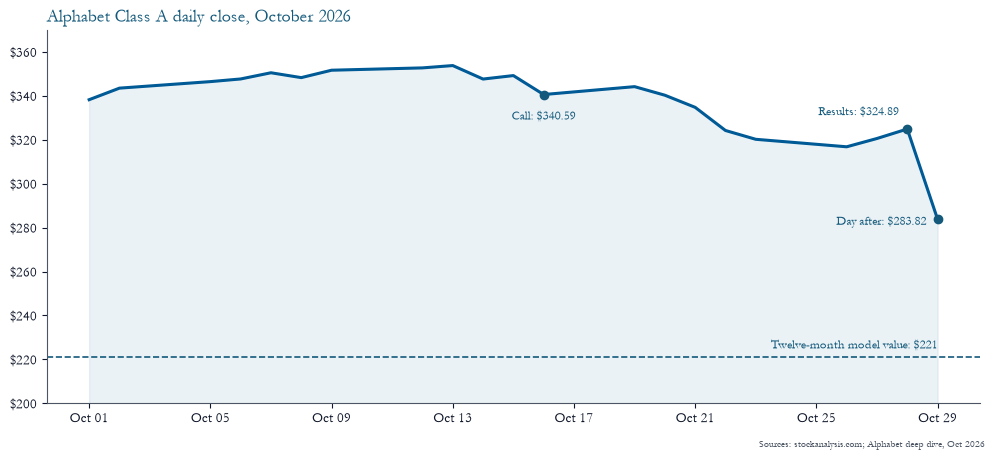

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.plot(prices.index, prices.values, color=BLUE_MAIN, lw=2.2)
ax.fill_between(prices.index, prices.values, 200, color=BLUE_MAIN, alpha=0.08)
ax.axhline(MODEL_VALUE, color=TITLE_BLUE, lw=1.2, ls="--")
ax.text(prices.index[-1], MODEL_VALUE + 4, f"Twelve-month model value: ${MODEL_VALUE}", ha="right", color=TITLE_BLUE, fontsize=9)
for day, label, offset, ha in [("2026-10-16", "Call: $340.59", (0, -18), "center"),
                               ("2026-10-28", "Results: $324.89", (-6, 10), "right"),
                               ("2026-10-29", "Day after: $283.82", (-8, -4), "right")]:
    d = pd.Timestamp(day)
    ax.scatter(d, prices[d], color=TITLE_BLUE, zorder=3, s=36)
    ax.annotate(label, (d, prices[d]), xytext=offset, textcoords="offset points", ha=ha, fontsize=9, color=TITLE_BLUE)
ax.set_ylim(200, 370)
ax.yaxis.set_major_formatter(lambda v, _: f"${v:.0f}")
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b %d"))
ax.set_title("Alphabet Class A daily close, October 2026", color=TITLE_BLUE, loc="left", fontsize=13)
fig.text(0.99, 0.01, "Sources: stockanalysis.com; Alphabet deep dive, Oct 2026", ha="right", va="bottom", fontsize=7.5, color=TEXT_MUTED)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

## Chart 2. Reported EPS against EPS without the marks

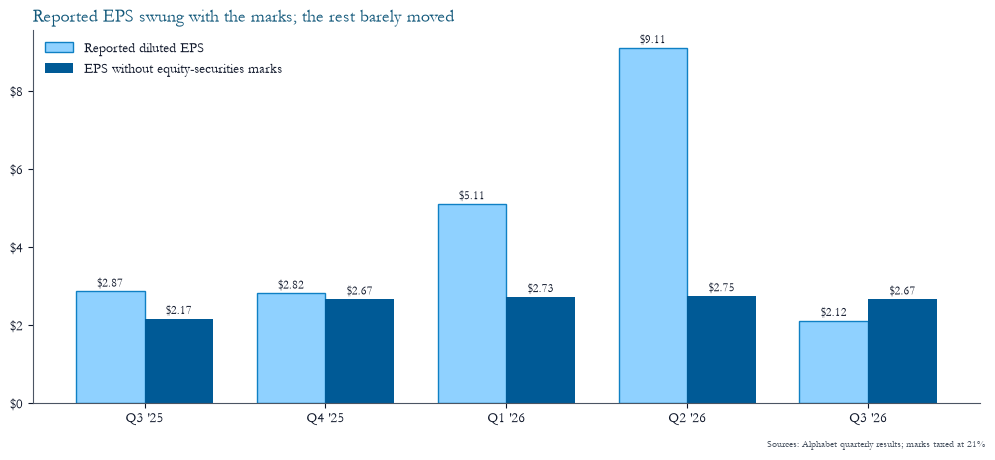

In [7]:
x = range(len(quarters))
w = 0.38
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.bar([i - w / 2 for i in x], q["diluted_eps"], w, color=BLUE_LIGHT, edgecolor=BLUE_SOFT, label="Reported diluted EPS")
ax.bar([i + w / 2 for i in x], core, w, color=BLUE_MAIN, label="EPS without equity-securities marks")
for i, (r, c) in enumerate(zip(q["diluted_eps"], core)):
    ax.text(i - w / 2, r + 0.12, f"${r:.2f}", ha="center", fontsize=8.5)
    ax.text(i + w / 2, c + 0.12, f"${c:.2f}", ha="center", fontsize=8.5)
ax.set_xticks(list(x), quarters)
ax.yaxis.set_major_formatter(lambda v, _: f"${v:.0f}")
ax.legend(frameon=False, loc="upper left")
ax.set_title("Reported EPS swung with the marks; the rest barely moved", color=TITLE_BLUE, loc="left", fontsize=13)
fig.text(0.99, 0.01, "Sources: Alphabet quarterly results; marks taxed at 21%", ha="right", va="bottom", fontsize=7.5, color=TEXT_MUTED)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

## Chart 3. Operating cash flow, capex and free cash flow

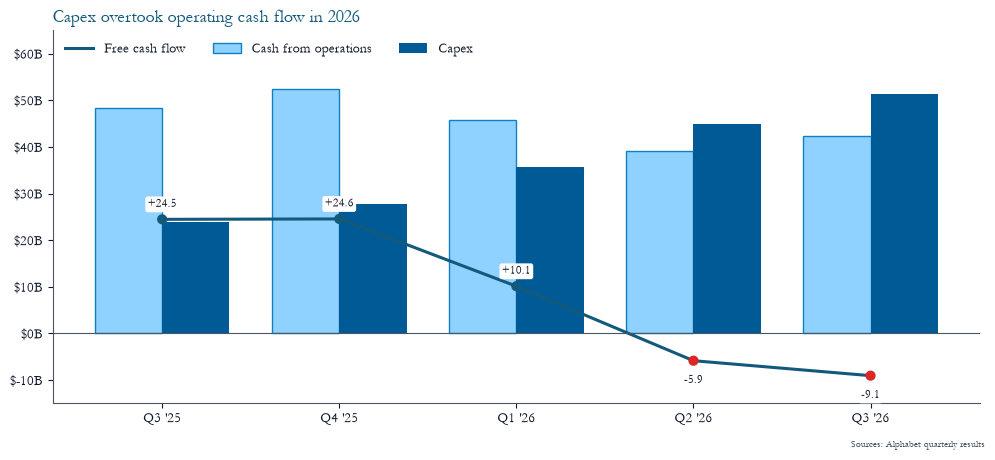

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.bar([i - w / 2 for i in x], q["operating_cash_flow"] / 1000, w, color=BLUE_LIGHT, edgecolor=BLUE_SOFT, label="Cash from operations")
ax.bar([i + w / 2 for i in x], q["capex"] / 1000, w, color=BLUE_MAIN, label="Capex")
fcf = q["free_cash_flow"] / 1000
ax.plot(list(x), fcf, color=TITLE_BLUE, lw=2.2, label="Free cash flow")
ax.scatter(list(x), fcf, color=[RED_SOFT if v < 0 else TITLE_BLUE for v in fcf], zorder=3, s=40)
for i, v in enumerate(fcf):
    ax.annotate(f"{v:+.1f}", (i, v), xytext=(0, -16 if v < 0 else 9), textcoords="offset points", ha="center", fontsize=8.5,
                bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none"))
ax.axhline(0, color=TEXT_MUTED, lw=0.8)
ax.set_xticks(list(x), quarters)
ax.yaxis.set_major_formatter(lambda v, _: f"${v:.0f}B")
ax.legend(frameon=False, loc="upper left", ncol=3)
ax.set_ylim(-15, 65)
ax.set_title("Capex overtook operating cash flow in 2026", color=TITLE_BLUE, loc="left", fontsize=13)
fig.text(0.99, 0.01, "Sources: Alphabet quarterly results", ha="right", va="bottom", fontsize=7.5, color=TEXT_MUTED)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

## Chart 4. Google Cloud revenue and operating margin

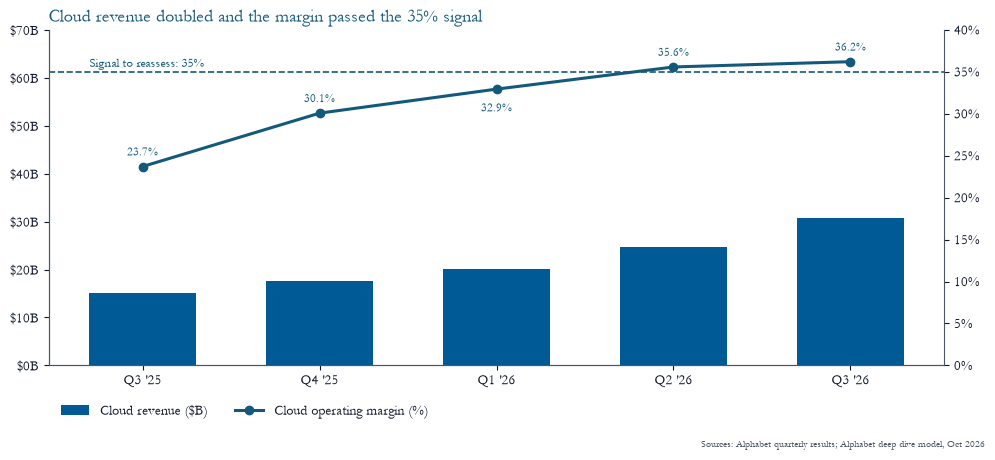

In [9]:
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.bar(list(x), q["cloud_revenue"] / 1000, 0.6, color=BLUE_MAIN, label="Cloud revenue ($B)")
ax.set_ylim(0, 70)
ax.yaxis.set_major_formatter(lambda v, _: f"${v:.0f}B")
ax2 = ax.twinx()
ax2.spines["right"].set_visible(True)
ax2.plot(list(x), q["cloud_margin_pct"], color=TITLE_BLUE, lw=2.2, marker="o", label="Cloud operating margin (%)")
for i, v in enumerate(q["cloud_margin_pct"]):
    # Labels just under the dashed base-case line go below their point so the two never touch
    below = 31 < v < SIGNAL_CLOUD_MARGIN
    ax2.annotate(f"{v:.1f}%", (i, v), xytext=(0, -16 if below else 8), textcoords="offset points", ha="center", fontsize=8.5, color=TITLE_BLUE)
ax2.axhline(SIGNAL_CLOUD_MARGIN, color=TITLE_BLUE, lw=1.2, ls="--")
ax2.text(-0.3, SIGNAL_CLOUD_MARGIN + 0.6, f"Signal to reassess: {SIGNAL_CLOUD_MARGIN}%", color=TITLE_BLUE, fontsize=9)
ax2.set_ylim(0, 40)
ax2.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
ax.set_xticks(list(x), quarters)
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, frameon=False, loc="upper left", bbox_to_anchor=(0, -0.08), ncol=2)
ax.set_title("Cloud revenue doubled and the margin passed the 35% signal", color=TITLE_BLUE, loc="left", fontsize=13)
fig.text(0.99, 0.01, "Sources: Alphabet quarterly results; Alphabet deep dive model, Oct 2026", ha="right", va="bottom", fontsize=7.5, color=TEXT_MUTED)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

Personal hobby project. For informational and educational purposes only, not investment advice. Model outputs are
assumption-dependent. Use at your own risk.